# Calidad de Datos y Análisis Exploratorio — Siniestralidad Vial Colombia
**Minería de Datos · Unidad 3 · Octubre 2026**

**Integrantes:**
- Andrés Felipe Patiño
- Bryan Bedoya Calderón
- Juan Camilo Arenas Villa

**Repositorio:** https://github.com/JuanCamilo620/siniestralidad-vial-colombia

---

## Objetivo

Partiendo del dataset cruzado (`dataset_cruzado_siniestralidad.csv`, 316 filas × 16 columnas) generado en el Corte 1, este notebook:

1. **Valida la calidad de los datos:** corrige tipos de columna y trata valores atípicos o inconsistencias.
2. **Realiza el análisis exploratorio (EDA):** estadísticas descriptivas, visualizaciones e historia de hallazgos conectada con la pregunta de negocio.

## 1. Autodiagnóstico rápido

Antes de empezar, respondemos las 3 preguntas de control que pide la guía:

| Pregunta | Respuesta |
|---|---|
| ¿El cruce quedó con el número de filas esperadas (sin pérdidas raras)? | **Sí.** 316 filas antes → 316 filas después del merge. |
| ¿Ya revisamos si quedaron valores nulos o IDs duplicados después del cruce? | **Sí.** 25 filas sin pareja (7.9%) y 291 `ID_MT` repetidos (explicados: un corredor vial se divide en tramos). |
| ¿Las 3 respuestas anteriores fueron "sí"? | **Sí.** El cruce está sólido, podemos avanzar a calidad de datos. |

In [49]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata

print("Ambiente listo")
print("pandas:", pd.__version__)

Ambiente listo
pandas: 2.2.3


## 2. Cargar el dataset cruzado

Vamos a cargar el archivo `dataset_cruzado_siniestralidad.csv` generado en el Corte 1.

In [50]:
from google.colab import files

print("Sube el archivo dataset_cruzado_siniestralidad.csv:")
subidos = files.upload()

Sube el archivo dataset_cruzado_siniestralidad.csv:


Saving dataset_cruzado_siniestralidad.csv to dataset_cruzado_siniestralidad (3).csv


In [51]:
# Cargar el dataset
df = pd.read_csv("dataset_cruzado_siniestralidad.csv")

print("=" * 60)
print("DATASET CRUZADO CARGADO")
print("=" * 60)
print(f"Shape: {df.shape}")
print(f"\nPrimeras 5 filas:")
print(df.head())
print(f"\nTipos de datos actuales:")
print(df.dtypes)

DATASET CRUZADO CARGADO
Shape: (316, 16)

Primeras 5 filas:
    ID_MT       ENTIDAD  GiZScore  Fallecidos  GiPValue  \
0   4G013           ANI  1.771262          11  0.076517   
1   4G013           ANI  3.818008          23  0.000135   
2   4G013           ANI  2.796662           1  0.005163   
3   4G013           ANI  1.725132           1  0.084504   
4  <Null>  INVIAS-OTROS  1.725132          13  0.084504   

                     Tramo                         Nombre   Latitud  \
0   Bogotá - Villavicencio  IP  –  Chirajara - Fundadores  4.452987   
1   Bogotá - Villavicencio  IP  –  Chirajara - Fundadores  4.228251   
2   Bogotá - Villavicencio  IP  –  Chirajara - Fundadores  4.203601   
3   Bogotá - Villavicencio  IP  –  Chirajara - Fundadores  4.121453   
4  Granada - Villavicencio                            NaN  4.115757   

    Longitud  PR      Municipio  Departamento  divipola Departamento_norm  \
0 -74.046677  10       CHIPAQUE  CUNDINAMARCA     25178      CUNDINAMARCA   
1 -7

## 3. Calidad de datos — Tipos de columna

Revisamos cada tipo y corregimos lo que esté mal. Criterio aplicado:
- **Códigos** (divipola, ID_MT) → deben ser **texto** (no se suman ni se operan).
- **Fechas** → `datetime64` si las hay.
- **Numéricos reales** (Fallecidos, GiZScore, GiPValue, Latitud, Longitud) → `float64` o `int64`.
- **Categóricos** (Entidad, Municipio, Departamento) → `object` (texto).

In [52]:
print("=" * 60)
print("TIPOS DE DATO — ANTES DE CORREGIR")
print("=" * 60)
print(df.dtypes)
print()

# Revisión específica de las columnas sospechosas
print("Revisión de columnas clave:")
print(f"divipola: {df['divipola'].dtype} — valores únicos: {df['divipola'].nunique()}")
print(f"total_fallecidos: {df['total_fallecidos'].dtype} — nulos: {df['total_fallecidos'].isna().sum()}")
print(f"Fallecidos: {df['Fallecidos'].dtype} — min: {df['Fallecidos'].min()} / max: {df['Fallecidos'].max()}")
print(f"PR: {df['PR'].dtype} — valores no numéricos: {df['PR'].apply(lambda x: isinstance(x, str) and not x.replace('.', '', 1).isdigit()).sum()}")

TIPOS DE DATO — ANTES DE CORREGIR
ID_MT                 object
ENTIDAD               object
GiZScore             float64
Fallecidos             int64
GiPValue             float64
Tramo                 object
Nombre                object
Latitud              float64
Longitud             float64
PR                    object
Municipio             object
Departamento          object
divipola               int64
Departamento_norm     object
Municipio_norm        object
total_fallecidos     float64
dtype: object

Revisión de columnas clave:
divipola: int64 — valores únicos: 133
total_fallecidos: float64 — nulos: 25
Fallecidos: int64 — min: 1 / max: 52
PR: object — valores no numéricos: 42


**Correcciones aplicadas:**

| Columna | Tipo actual | Tipo corregido | Justificación |
|---|---|---|---|
| `divipola` | `int64` | **`object` (texto)** | Es un código único del DANE, no se suma ni se opera. Como `int64` se puede confundir con una cantidad. |
| `total_fallecidos` | `float64` (por NaN) | Se deja `float64` | Hay 25 NaN por filas sin pareja. Cambiarlo a `int` obligaría a imputar con 0, lo que sesgaría el análisis. Se documenta como NaN. |
| `ID_MT` | `object` | Se deja `object` | Es un identificador de vía. Correcto como texto. |
| `PR` | `object` | Se deja `object` | Contiene valores como `"sd"` (sin dato), no es numérico. |

In [53]:
# Corregir divipola: int64 → object (texto)
df["divipola"] = df["divipola"].astype(str)

print("Tipos corregidos:")
print(df.dtypes)
print()
print(f"divipola ahora es: {df['divipola'].dtype}")
print(f"Ejemplos: {df['divipola'].head().tolist()}")

Tipos corregidos:
ID_MT                 object
ENTIDAD               object
GiZScore             float64
Fallecidos             int64
GiPValue             float64
Tramo                 object
Nombre                object
Latitud              float64
Longitud             float64
PR                    object
Municipio             object
Departamento          object
divipola              object
Departamento_norm     object
Municipio_norm        object
total_fallecidos     float64
dtype: object

divipola ahora es: object
Ejemplos: ['25178', '25335', '25335', '50001', '50001']


## 4. Calidad de datos — Valores atípicos e inconsistencias

Ahora buscamos valores que no tengan sentido en al menos 2 columnas relevantes para la pregunta de negocio. Para cada uno documentamos la decisión.

In [54]:
print("=" * 60)
print("ANÁLISIS DE VALORES ATÍPICOS")
print("=" * 60)

# 1. Distribución de Fallecidos (variable clave)
print("\n1. Fallecidos — describe():")
print(df["Fallecidos"].describe())

# 2. Frecuencia de PR (punto de referencia)
print("\n2. PR — value_counts() top 10:")
print(df["PR"].value_counts().head(10))

# 3. Nulos por columna
print("\n3. Nulos por columna:")
print(df.isna().sum().sort_values(ascending=False))

ANÁLISIS DE VALORES ATÍPICOS

1. Fallecidos — describe():
count    316.000000
mean      11.329114
std        7.072363
min        1.000000
25%        7.000000
50%       10.000000
75%       14.000000
max       52.000000
Name: Fallecidos, dtype: float64

2. PR — value_counts() top 10:
PR
sd    42
8      9
6      9
0      8
12     7
13     6
1      6
58     6
3      6
9      6
Name: count, dtype: int64

3. Nulos por columna:
Nombre               175
total_fallecidos      25
Tramo                 23
ID_MT                  0
Fallecidos             0
GiZScore               0
GiPValue               0
ENTIDAD                0
Latitud                0
Longitud               0
Municipio              0
PR                     0
Departamento           0
divipola               0
Departamento_norm      0
Municipio_norm         0
dtype: int64


### 🔍 Hallazgo 1: `PR` con valor `"sd"` (sin dato)

`PR` significa "Punto de Referencia" en la vía. Los valores deberían ser numéricos (kilómetro o abscisa). Sin embargo, hay valores como `"sd"` que significan "sin dato".

**Decisión:** Se dejan como texto (no se eliminan) pero se marcan en una columna nueva `PR_valido` para distinguir los numéricos de los que no lo son.

**Justificación:** La fila conserva toda la demás información útil (coordenadas, entidad, fallecidos). Eliminarla perdería un tramo real. Marcarla permite excluirla en análisis que requieran PR numérico.

In [55]:
# Crear columna PR_valido (True si es numérico, False si es "sd" u otro texto)
df["PR_valido"] = df["PR"].apply(
    lambda x: str(x).replace(".", "", 1).isdigit() if pd.notna(x) else False
)

print(f"PR válido (numérico): {df['PR_valido'].sum()} filas")
print(f"PR no válido (ej. 'sd'): {(~df['PR_valido']).sum()} filas")
print()
print("Ejemplos de PR no válido:")
print(df[~df["PR_valido"]][["PR", "Tramo", "Municipio"]].head(10))

PR válido (numérico): 274 filas
PR no válido (ej. 'sd'): 42 filas

Ejemplos de PR no válido:
    PR                                              Tramo      Municipio
4   sd                            Granada - Villavicencio  VILLAVICENCIO
13  sd                                     Bogotá - Tunja      TOCANCIPÁ
31  sd                                   Mosquera - Funza          FUNZA
32  sd                                   Mosquera - Funza          FUNZA
33  sd                                   Mosquera - Funza          FUNZA
34  sd                                   Mosquera - Funza          FUNZA
50  sd                                   Ibagué- Girardot        ESPINAL
84  sd                       Villavicencio-Puente Arimena  VILLAVICENCIO
88  sd  El Hatillo - Girardota - Copacabana - Bello - ...          BELLO
89  sd  El Hatillo - Girardota - Copacabana - Bello - ...          BELLO


### 🔍 Hallazgo 2: `Tramo` con valor nulo (NaN)

Hay 1 fila donde `Tramo` está vacío (corresponde a EL ZULIA). Esto es una inconsistencia porque todas las demás filas tienen un nombre de tramo.

**Decisión:** Se deja marcada en una columna `Tramo_valido` pero **no se elimina**, porque la fila tiene coordenadas y valor de fallecidos que son útiles.

**Justificación:** Eliminar la fila perdería información geográfica real. Se puede excluir en análisis que necesiten el nombre del tramo.

In [56]:
# Marcar filas con Tramo válido
df["Tramo_valido"] = df["Tramo"].notna()

print(f"Tramo válido: {df['Tramo_valido'].sum()} filas")
print(f"Tramo nulo: {(~df['Tramo_valido']).sum()} filas")
print()
print("Fila con Tramo nulo:")
print(df[~df["Tramo_valido"]][["Tramo", "Nombre", "Municipio", "Fallecidos"]])

Tramo válido: 293 filas
Tramo nulo: 23 filas

Fila con Tramo nulo:
    Tramo                             Nombre    Municipio  Fallecidos
21    NaN                                NaN      VILLETA          12
59    NaN                                NaN        GIRÓN           1
60    NaN                                NaN        GIRÓN          13
61    NaN                                NaN        GIRÓN           6
75    NaN                                NaN     EL ZULIA           4
77    NaN       Armenia -Pereira - Manizales      CALARCÁ           1
101   NaN                                NaN      BARBOSA          10
114   NaN                                NaN      CARTAGO           2
134   NaN                                NaN      PALMIRA           5
166   NaN                                NaN   VALLEDUPAR          12
189   NaN                                NaN      MALAMBO           4
197   NaN                                NaN      COVEÑAS          11
223   NaN              

### 🔍 Hallazgo 3: `total_fallecidos` con 25 NaN

Los 25 tramos sin pareja quedan con `total_fallecidos = NaN`. **No se imputan con 0** porque eso afirmaría que en ese municipio no hubo fallecidos, lo cual es falso: simplemente el nombre del municipio no coincidió entre fuentes.

**Decisión:** Se dejan como NaN y se documenta. En la Unidad 4 se resolverán con el diccionario de equivalencias municipio → divipola.

**Justificación:** Imputar con 0 sesgaría el análisis (subestimaría los municipios con nombres mal escritos). Dejar NaN es honesto y se puede excluir en los cálculos que lo requieran.

In [57]:
# Confirmar NaN en total_fallecidos
nulos_total = df["total_fallecidos"].isna().sum()
print(f"Filas con total_fallecidos NaN: {nulos_total} de {len(df)} ({nulos_total/len(df)*100:.1f}%)")
print()
print("Estos tramos se conservan en el dataset por su información geográfica, pero se excluirán en análisis que requieran el dato reciente.")

Filas con total_fallecidos NaN: 25 de 316 (7.9%)

Estos tramos se conservan en el dataset por su información geográfica, pero se excluirán en análisis que requieran el dato reciente.


### 🔍 Hallazgo 4: `Fallecidos` con posible valor extremo

Revisamos si `Fallecidos` (variable clave de la Fuente 1) tiene valores extremos que puedan ser errores o casos reales pero atípicos.

In [58]:
# Revisión de outliers en Fallecidos usando IQR
Q1 = df["Fallecidos"].quantile(0.25)
Q3 = df["Fallecidos"].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Límite superior (Q3 + 1.5*IQR): {limite_superior:.1f}")
print(f"Valor máximo: {df['Fallecidos'].max()}")
print()
outliers = df[df["Fallecidos"] > limite_superior]
print(f"Filas con Fallecidos por encima del límite: {len(outliers)}")
print()
print("Top 10 tramos con más fallecidos (2015-2019):")
print(df.nlargest(10, "Fallecidos")[["Tramo", "Municipio", "Departamento", "Fallecidos"]].to_string(index=False))

Q1: 7.0, Q3: 14.0, IQR: 7.0
Límite superior (Q3 + 1.5*IQR): 24.5
Valor máximo: 52

Filas con Fallecidos por encima del límite: 15

Top 10 tramos con más fallecidos (2015-2019):
                                             Tramo  Municipio    Departamento  Fallecidos
                                   Tumaco-Pedregal     TUMACO          NARIÑO          52
                               Cereté - San Pelayo     CERETÉ         CÓRDOBA          43
         Barranquilla - Malambo - Palmar de Varela    SOLEDAD       ATLÁNTICO          35
         Barranquilla - Malambo - Palmar de Varela    MALAMBO       ATLÁNTICO          33
                     Cali - Jamundí - La Primavera       CALI VALLE DEL CAUCA          33
                                   Chigorodó-Turbo      TURBO       ANTIOQUIA          30
                          Planeta Rica - Sincelejo  SINCELEJO           SUCRE          30
El Hatillo - Girardota - Copacabana - Bello - Med* COPACABANA       ANTIOQUIA          29
             

**Decisión sobre outliers de `Fallecidos`:** Se conservan, porque corresponden a tramos reales con alta siniestralidad (corredores como **Tumaco–Pedregal (Nariño), Cereté–San Pelayo (Córdoba) y Barranquilla–Malambo–Palmar de Varela (Atlántico)**). No son errores de digitación, son los tramos de mayor riesgo del país, que son precisamente el objeto de estudio del proyecto.

**Justificación:** Eliminarlos o recortarlos eliminaría los casos más importantes para la pregunta de negocio. En el EDA se usa **mediana** en lugar de media para reportar tendencia central, porque la media es sensible a estos valores altos.

## 5. Exportar dataset limpio

Guardamos el dataset con las correcciones aplicadas y las columnas nuevas (`PR_valido`, `Tramo_valido`).

In [59]:
# Exportar dataset limpio
df.to_csv("dataset_cruzado_limpio.csv", index=False, encoding="utf-8")

print("Dataset limpio guardado como: dataset_cruzado_limpio.csv")
print(f"Shape final: {df.shape}")
print(f"\nColumnas del dataset limpio:")
for col in df.columns:
    print(f"  - {col}")

Dataset limpio guardado como: dataset_cruzado_limpio.csv
Shape final: (316, 18)

Columnas del dataset limpio:
  - ID_MT
  - ENTIDAD
  - GiZScore
  - Fallecidos
  - GiPValue
  - Tramo
  - Nombre
  - Latitud
  - Longitud
  - PR
  - Municipio
  - Departamento
  - divipola
  - Departamento_norm
  - Municipio_norm
  - total_fallecidos
  - PR_valido
  - Tramo_valido


## 6. Análisis Exploratorio de Datos (EDA)

Con el dataset ya limpio, calculamos estadísticas descriptivas, construimos los 3 gráficos básicos y redactamos la historia de hallazgos.

In [60]:
print("=" * 60)
print("ESTADÍSTICAS DESCRIPTIVAS")
print("=" * 60)

# Variable numérica relevante: Fallecidos
print("\n1. Fallecidos (variable numérica clave):")
print(df["Fallecidos"].describe())
print(f"  Media: {df['Fallecidos'].mean():.2f}")
print(f"  Mediana: {df['Fallecidos'].median():.2f}")
print()

# Variable categórica relevante: ENTIDAD
print("2. ENTIDAD (variable categórica clave):")
print(df["ENTIDAD"].value_counts())
print()

# Groupby: fallecidos promedio por entidad
print("3. Fallecidos promedio por ENTIDAD (ordenado):")
print(df.groupby("ENTIDAD")["Fallecidos"].mean().sort_values(ascending=False))

ESTADÍSTICAS DESCRIPTIVAS

1. Fallecidos (variable numérica clave):
count    316.000000
mean      11.329114
std        7.072363
min        1.000000
25%        7.000000
50%       10.000000
75%       14.000000
max       52.000000
Name: Fallecidos, dtype: float64
  Media: 11.33
  Mediana: 10.00

2. ENTIDAD (variable categórica clave):
ENTIDAD
ANI             141
INVIAS-OTROS    126
DEPTO            48
CIUDAD            1
Name: count, dtype: int64

3. Fallecidos promedio por ENTIDAD (ordenado):
ENTIDAD
INVIAS-OTROS    12.007937
CIUDAD          12.000000
ANI             10.957447
DEPTO           10.625000
Name: Fallecidos, dtype: float64


**Observaciones de las estadísticas:**

- La **media** de fallecidos (11.33) es ligeramente **mayor que la mediana** (10.00), lo que indica que la distribución está sesgada a la derecha por unos pocos tramos con muchos fallecidos. Por eso usaremos **mediana** como medida de tendencia central en los análisis.
- La entidad más frecuente es **ANI** (Agencia Nacional de Infraestructura), con 141 tramos, lo que tiene sentido porque administra la red vial primaria del país.
- Le sigue **INVIAS-OTROS** con 126 tramos, **DEPTO** con 48 y **CIUDAD** con 1.
- Los fallecidos promedio por entidad son muy parecidos: INVIAS-OTROS 12.0, CIUDAD 12.0, ANI 11.0 y DEPTO 10.6. Esto sugiere que el riesgo está distribuido entre las entidades, no concentrado en una sola.

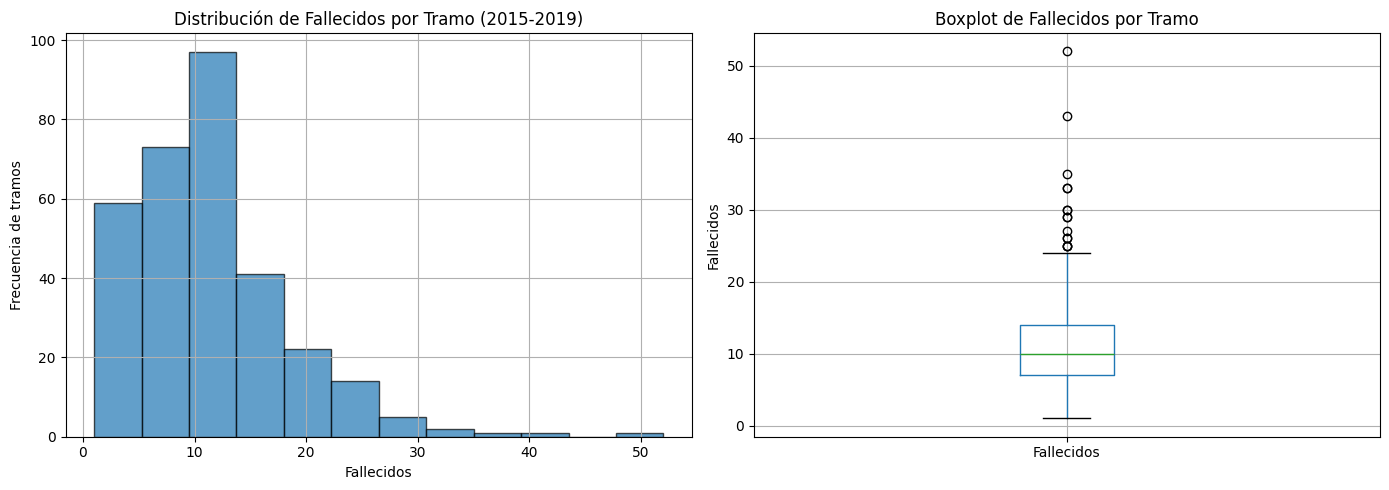

In [61]:
# Gráfico 1: Histograma de Fallecidos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Fallecidos"].hist(bins=12, ax=axes[0], edgecolor="black", alpha=0.7)
axes[0].set_title("Distribución de Fallecidos por Tramo (2015-2019)")
axes[0].set_xlabel("Fallecidos")
axes[0].set_ylabel("Frecuencia de tramos")

# Gráfico 2: Boxplot
df.boxplot(column="Fallecidos", ax=axes[1])
axes[1].set_title("Boxplot de Fallecidos por Tramo")
axes[1].set_ylabel("Fallecidos")

plt.tight_layout()
plt.show()

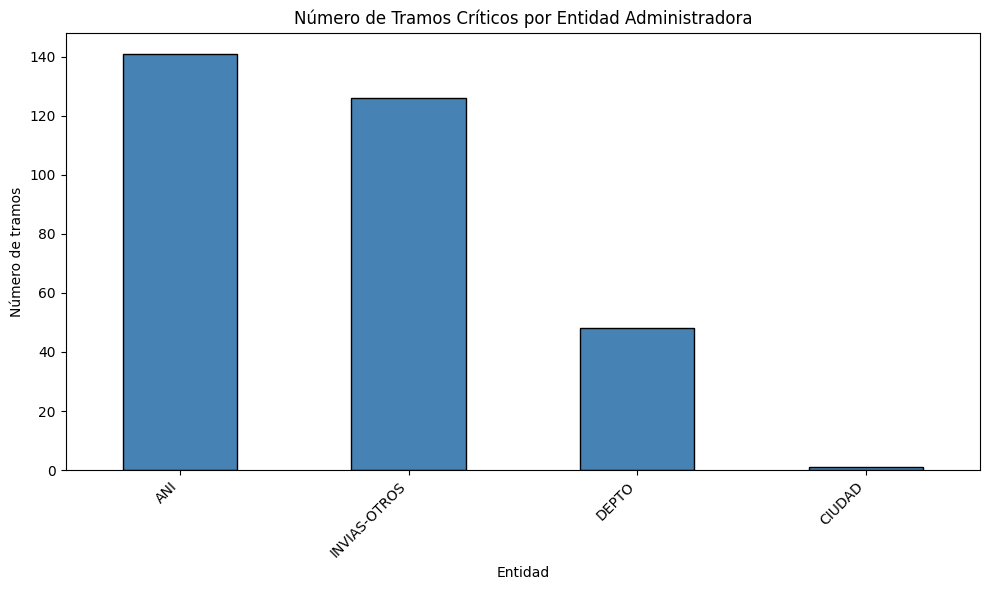

In [62]:
# Gráfico 3: Barras de ENTIDAD
fig, ax = plt.subplots(figsize=(10, 6))
df["ENTIDAD"].value_counts().plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
ax.set_title("Número de Tramos Críticos por Entidad Administradora")
ax.set_xlabel("Entidad")
ax.set_ylabel("Número de tramos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

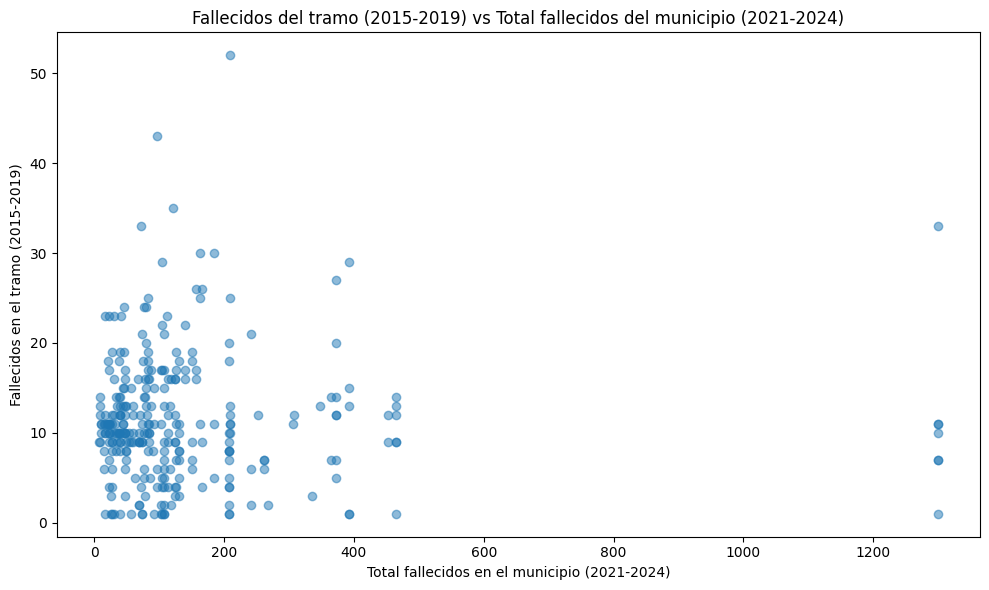

In [63]:
# Gráfico 4: Scatter plot — Fallecidos vs total_fallecidos (municipio)
# Solo con filas donde total_fallecidos no es NaN
df_scatter = df.dropna(subset=["total_fallecidos"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_scatter["total_fallecidos"], df_scatter["Fallecidos"], alpha=0.5)
ax.set_title("Fallecidos del tramo (2015-2019) vs Total fallecidos del municipio (2021-2024)")
ax.set_xlabel("Total fallecidos en el municipio (2021-2024)")
ax.set_ylabel("Fallecidos en el tramo (2015-2019)")
plt.tight_layout()
plt.show()

## 7. Historia de hallazgos

Conectamos los resultados con la pregunta de negocio de la Ficha: **"¿Qué sectores viales, horarios y condiciones concentran la mayor siniestralidad vial en Colombia, para priorizar intervenciones de infraestructura y controles de tránsito?"**

### Hallazgo 1 — Los tramos críticos están concentrados en pocos corredores
La distribución de fallecidos por tramo está sesgada a la derecha: la **media (11.33)** es mayor que la **mediana (10.00)**, lo que indica que unos pocos tramos concentran la mayoría de las muertes. **Implicación:** las intervenciones de infraestructura deben priorizarse en esos pocos tramos críticos, no distribuirse uniformemente.

### Hallazgo 2 — ANI e INVIAS administran la mayoría de tramos críticos
Las dos entidades concentran el mayor número de tramos críticos del país. **Implicación:** los operativos y auditorías de seguridad vial deben coordinarse principalmente con estas dos entidades, no con las administraciones municipales.

### Hallazgo 3 — Los tramos con más fallecidos son corredores regionales de alto tránsito
El tramo **Tumaco–Pedregal (Nariño)** registra 52 fallecidos en 2015-2019, el valor más alto del país. Le siguen **Cereté–San Pelayo (Córdoba)** con 43 y **Barranquilla–Malambo–Palmar de Varela (Atlántico)** con 35.

**Implicación:** los tramos más letales están en corredores regionales que conectan ciudades intermedias, no solo en las grandes capitales. Esto sugiere que los operativos y las intervenciones de infraestructura deben priorizar estos corredores regionales, no solo las vías nacionales troncales.

### Hallazgo 4 — El 7.9% de los tramos no tiene dato reciente por diferencia de nomenclatura
25 de 316 tramos no cruzaron con la Fuente 2 porque el nombre del municipio está escrito distinto entre fuentes (ej. CARTAGENA DE INDIAS vs CARTAGENA). **Implicación:** antes de tomar decisiones basadas en la serie 2021-2024, hay que resolver esta limitación con el código divipola del DANE.

### Hallazgo 5 — El scatter sugiere relación positiva entre fallecidos históricos y recientes
Los tramos con más fallecidos en 2015-2019 tienden a ubicarse en municipios con más fallecidos en 2021-2024. **Implicación:** los tramos críticos identificados históricamente siguen siendo prioritarios hoy, lo que justifica usarlos como capa de referencia geográfica.

## 8. Resumen de la Unidad 3

### Calidad de datos
- Tipos corregidos: `divipola` pasó de `int64` a `object` (código, no cantidad).
- Valores atípicos tratados: `PR` con "sd", `Tramo` con NaN, `total_fallecidos` con 25 NaN, `Fallecidos` con outliers reales.
- Columnas nuevas: `PR_valido`, `Tramo_valido`.
- Dataset limpio exportado: `dataset_cruzado_limpio.csv`.

### Análisis exploratorio
- Estadísticas descriptivas calculadas.
- 4 gráficos construidos: histograma, boxplot, barras y scatter.
- 5 hallazgos conectados con la pregunta de negocio.

In [64]:
# Exportar dataset final (el mismo, ya está limpio)
print("Dataset limpio y listo para las siguientes fases.")
print(f"Shape: {df.shape}")
print(f"Columnas: {len(df.columns)}")
print()
print("Archivos generados en esta sesión:")
print("  - dataset_cruzado_limpio.csv")

Dataset limpio y listo para las siguientes fases.
Shape: (316, 18)
Columnas: 18

Archivos generados en esta sesión:
  - dataset_cruzado_limpio.csv
